# Oral Cavity Segmentation Pipeline

## 1. Environment Check

In [1]:
import sys, platform
import tensorflow as tf

print("Python:", sys.version)
print("Platform:", platform.platform())
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))


Python: 3.13.15 (main, Aug  5 2026, 12:25:43) [Clang 21.0.0 (clang-2100.1.1.101)]
Platform: macOS-26.6.1-arm64-arm-64bit-Mach-O
TensorFlow: 2.21.0
GPUs: []


## Imports

In [2]:
import os
import json
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models, backend as K

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


## Config & Output Folder

In [3]:
OUTPUT_DIR = Path("/Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MASKS_DIR = OUTPUT_DIR / "masks"
MASKS_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 25

print("Output folder:", OUTPUT_DIR)


Output folder: /Users/annapoornaak/Desktop/College /Oral Cancer/Segmentation Output


## 2. Dataset `Categories` Folder

In [4]:
DATASET_DIR = Path(
    "/Users/annapoornaak/Desktop/College /Oral Cancer/Dataset/Zenodo/Categories"
)

print("Categories folder:", DATASET_DIR)
print("Exists:", DATASET_DIR.exists())


Categories folder: /Users/annapoornaak/Desktop/College /Oral Cancer/Dataset/Zenodo/Categories
Exists: True


## 3. COCO Annotation JSON

In [5]:
ANNOTATION_FILE = Path(
    "/Users/annapoornaak/Desktop/College /Oral Cancer/Dataset/Zenodo/Dataset/Annotation.json"
)

print("Annotation file:", ANNOTATION_FILE)
print("Exists:", ANNOTATION_FILE.exists())


Annotation file: /Users/annapoornaak/Desktop/College /Oral Cancer/Dataset/Zenodo/Dataset/Annotation.json
Exists: True


## 4. Load & Verify `Lesion` and `Oral Cavity` Categories

In [6]:
with open(ANNOTATION_FILE, "r") as f:
    coco = json.load(f)

print("Images:", len(coco["images"]))
print("Annotations:", len(coco["annotations"]))
print("Categories:", coco["categories"])

name_to_id = {c["name"]: c["id"] for c in coco["categories"]}
assert "Lesion" in name_to_id, "Lesion category not found"
assert "Oral Cavity" in name_to_id, "Oral Cavity category not found"

CATEGORY_ID_LESION = name_to_id["Lesion"]
CATEGORY_ID_ORAL = name_to_id["Oral Cavity"]

print("Lesion id:", CATEGORY_ID_LESION)
print("Oral Cavity id:", CATEGORY_ID_ORAL)

category_counts = Counter(ann["category_id"] for ann in coco["annotations"])
for c in coco["categories"]:
    print(c["name"], "->", category_counts[c["id"]], "annotations")


Images: 3000
Annotations: 6358
Categories: [{'id': 1, 'name': 'Lesion', 'supercategory': 'object'}, {'id': 2, 'name': 'Oral Cavity', 'supercategory': 'object'}]
Lesion id: 1
Oral Cavity id: 2
Lesion -> 3358 annotations
Oral Cavity -> 3000 annotations


## 5. Match Annotation Images to Category Folders

In [7]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

filename_to_path = {}
for path in DATASET_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in image_extensions:
        filename_to_path[path.name] = path

images_info = {img["id"]: img for img in coco["images"]}

matched, unmatched = 0, 0
image_id_to_path = {}

for image_id, info in images_info.items():
    fname = Path(info["file_name"]).name
    if fname in filename_to_path:
        image_id_to_path[image_id] = filename_to_path[fname]
        matched += 1
    else:
        unmatched += 1

print("Matched:", matched)
print("Unmatched:", unmatched)


Matched: 3000
Unmatched: 0


## Data Exploration: Annotation.json

In [8]:
print("Total images in JSON:", len(coco["images"]))
print("Total annotations in JSON:", len(coco["annotations"]))
print("Total categories:", len(coco["categories"]))
print()

for c in coco["categories"]:
    print(c)


Total images in JSON: 3000
Total annotations in JSON: 6358
Total categories: 2

{'id': 1, 'name': 'Lesion', 'supercategory': 'object'}
{'id': 2, 'name': 'Oral Cavity', 'supercategory': 'object'}


In [9]:
# annotations per image
anns_per_image = Counter(ann["image_id"] for ann in coco["annotations"])

all_image_ids = set(images_info.keys())
annotated_image_ids = set(anns_per_image.keys())
unannotated_image_ids = all_image_ids - annotated_image_ids

print("Images WITH at least one annotation:", len(annotated_image_ids))
print("Images WITH NO annotation:", len(unannotated_image_ids))
print("Sanity check (should equal total images):",
      len(annotated_image_ids) + len(unannotated_image_ids), "==", len(all_image_ids))


Images WITH at least one annotation: 3000
Images WITH NO annotation: 0
Sanity check (should equal total images): 3000 == 3000


In [10]:
# category id -> set of image ids having that category
image_category_map = {}
for ann in coco["annotations"]:
    image_category_map.setdefault(ann["image_id"], set()).add(ann["category_id"])

has_lesion = {i for i, cats in image_category_map.items() if CATEGORY_ID_LESION in cats}
has_oral = {i for i, cats in image_category_map.items() if CATEGORY_ID_ORAL in cats}
has_both = has_lesion & has_oral
only_lesion = has_lesion - has_oral
only_oral = has_oral - has_lesion

print("Images with Lesion annotation:", len(has_lesion))
print("Images with Oral Cavity annotation:", len(has_oral))
print("Images with BOTH:", len(has_both))
print("Images with ONLY Lesion:", len(only_lesion))
print("Images with ONLY Oral Cavity:", len(only_oral))
print("Images with NEITHER (0 annotations):", len(unannotated_image_ids))


Images with Lesion annotation: 2271
Images with Oral Cavity annotation: 2999
Images with BOTH: 2270
Images with ONLY Lesion: 1
Images with ONLY Oral Cavity: 729
Images with NEITHER (0 annotations): 0


count    3000.000000
mean        2.119333
std         1.034142
min         1.000000
25%         2.000000
50%         2.000000
75%         2.000000
max         9.000000
dtype: float64

Distribution of annotation count per image:
1     729
2    1620
3     384
4     168
5      59
6      19
7      15
8       3
9       3
Name: count, dtype: int64


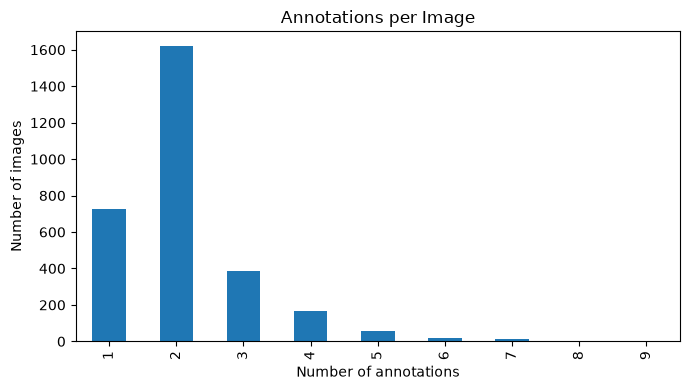

In [11]:
# annotations per image distribution
ann_counts = pd.Series(anns_per_image)
print(ann_counts.describe())
print()
print("Distribution of annotation count per image:")
print(ann_counts.value_counts().sort_index())

plt.figure(figsize=(7, 4))
ann_counts.value_counts().sort_index().plot(kind="bar")
plt.title("Annotations per Image")
plt.xlabel("Number of annotations")
plt.ylabel("Number of images")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "annotations_per_image.png", dpi=150)
plt.show()


      category  annotation_count
0       Lesion              3358
1  Oral Cavity              3000


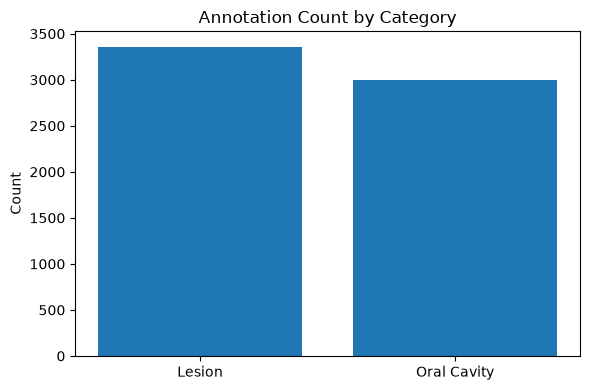

In [12]:
# category-wise annotation counts + bar chart
category_counts = Counter(ann["category_id"] for ann in coco["annotations"])
cat_names = {c["id"]: c["name"] for c in coco["categories"]}

cat_df = pd.DataFrame([
    {"category": cat_names[cid], "annotation_count": count}
    for cid, count in category_counts.items()
])
print(cat_df)

plt.figure(figsize=(6, 4))
plt.bar(cat_df["category"], cat_df["annotation_count"])
plt.title("Annotation Count by Category")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "annotation_counts_by_category.png", dpi=150)
plt.show()


In [13]:
# summary table: annotated vs unannotated vs matched-to-disk
summary = pd.DataFrame([
    {"metric": "Total images (JSON)", "count": len(coco["images"])},
    {"metric": "Total annotations (JSON)", "count": len(coco["annotations"])},
    {"metric": "Images with annotations", "count": len(annotated_image_ids)},
    {"metric": "Images with no annotations", "count": len(unannotated_image_ids)},
    {"metric": "Images with Lesion", "count": len(has_lesion)},
    {"metric": "Images with Oral Cavity", "count": len(has_oral)},
    {"metric": "Images with both", "count": len(has_both)},
    {"metric": "Images with only Lesion", "count": len(only_lesion)},
    {"metric": "Images with only Oral Cavity", "count": len(only_oral)},
    {"metric": "Images matched to files on disk", "count": matched},
    {"metric": "Images NOT matched to files on disk", "count": unmatched},
])
summary.to_csv(OUTPUT_DIR / "annotation_summary.csv", index=False)
summary


,metric,count
0,Total images (JSON),3000
1,Total annotations (JSON),6358
2,Images with annotations,3000
3,Images with no annotations,0
4,Images with Lesion,2271
5,Images with Oral Cavity,2999
6,Images with both,2270
7,Images with only Lesion,1
8,Images with only Oral Cavity,729
9,Images matched to files on disk,3000


## 6. Create Oral Cavity Binary Masks

In [14]:
oral_annotations_by_image = {}
for ann in coco["annotations"]:
    if ann["category_id"] != CATEGORY_ID_ORAL:
        continue
    oral_annotations_by_image.setdefault(ann["image_id"], []).append(ann)

print("Images with oral cavity annotations:", len(oral_annotations_by_image))

def create_oral_cavity_mask(image_id):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        return None

    image = cv2.imread(str(image_path))

    if image is None:
        return None

    height, width = image.shape[:2]
    # Black binary mask
    mask = np.zeros((height, width), dtype=np.uint8)

    for ann in oral_annotations_by_image.get(image_id, []):
        segmentation = ann.get("segmentation", [])
        # Skip invalid segmentation
        if not segmentation:
            continue

        # COCO polygon can be either:
        # [x1,y1,x2,y2,...]
        # OR
        # [[x1,y1,x2,y2,...], [...]]
        
        if isinstance(segmentation[0], (int, float)):
            polygons = [segmentation]
        else:
            polygons = segmentation

        for polygon in polygons:

            # Make sure polygon is valid
            if len(polygon) < 6:
                continue

            points = np.array(
                polygon,
                dtype=np.float32
            ).reshape(-1, 2)

            points = np.round(points).astype(np.int32)

            # Keep coordinates inside image
            points[:, 0] = np.clip(
                points[:, 0],
                0,
                width - 1
            )

            points[:, 1] = np.clip(
                points[:, 1],
                0,
                height - 1
            )

            # Fill polygon
            cv2.fillPoly(
                mask,
                [points],
                255
            )

    return mask

test_image_id = list(oral_annotations_by_image.keys())[0]
test_mask = create_oral_cavity_mask(test_image_id)
print("Test image ID:", test_image_id)
print("Mask shape:", test_mask.shape)
print("Unique values:", np.unique(test_mask))


Images with oral cavity annotations: 2999
Test image ID: 1
Mask shape: (3456, 4608)
Unique values: [  0 255]


## 7. Visually Verify Masks

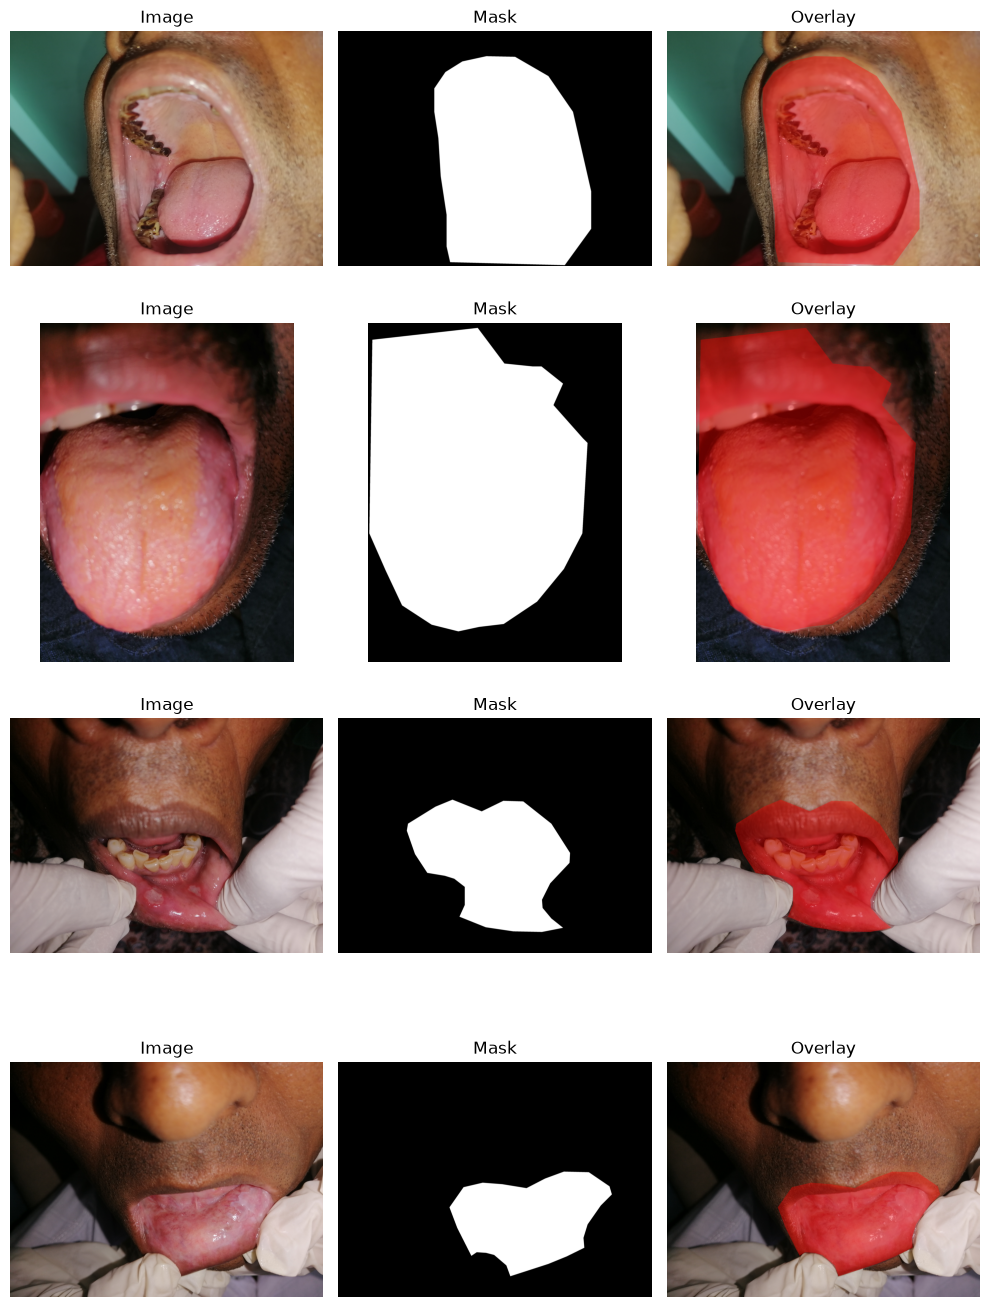

In [15]:
sample_ids = random.sample(list(oral_annotations_by_image.keys()), 4)

fig, axes = plt.subplots(4, 3, figsize=(10, 14))
for row, image_id in enumerate(sample_ids):
    image_path = image_id_to_path[image_id]
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    mask = create_oral_cavity_mask(image_id)
    overlay = image.copy()
    overlay[mask > 0] = [255, 0, 0]
    blended = cv2.addWeighted(image, 0.6, overlay, 0.4, 0)

    axes[row, 0].imshow(image); axes[row, 0].set_title("Image"); axes[row, 0].axis("off")
    axes[row, 1].imshow(mask, cmap="gray"); axes[row, 1].set_title("Mask"); axes[row, 1].axis("off")
    axes[row, 2].imshow(blended); axes[row, 2].set_title("Overlay"); axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mask_verification.png", dpi=150)
plt.show()


## 8. Generate Complete Image-Mask Dataset

In [16]:
from tqdm import tqdm
records = []

for image_id in tqdm(list(oral_annotations_by_image.keys())):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        continue

    mask = create_oral_cavity_mask(image_id)
    if mask is None:
        continue

    mask_path = MASKS_DIR / f"{image_id}.png"
    cv2.imwrite(str(mask_path), mask)

    records.append({
        "image_id": image_id,
        "image_path": str(image_path),
        "mask_path": str(mask_path),
    })

dataset_df = pd.DataFrame(records)
dataset_df.to_csv(OUTPUT_DIR / "dataset_index.csv", index=False)

print("Total image-mask pairs:", len(dataset_df))
dataset_df.head()


100%|██████████| 2999/2999 [01:28<00:00, 33.80it/s]

Total image-mask pairs: 2999


,image_id,image_path,mask_path
0,1,/Users/annapoornaak/Desktop/College /Oral Canc...,/Users/annapoornaak/Desktop/College /Oral Canc...
1,2,/Users/annapoornaak/Desktop/College /Oral Canc...,/Users/annapoornaak/Desktop/College /Oral Canc...
2,3,/Users/annapoornaak/Desktop/College /Oral Canc...,/Users/annapoornaak/Desktop/College /Oral Canc...
3,4,/Users/annapoornaak/Desktop/College /Oral Canc...,/Users/annapoornaak/Desktop/College /Oral Canc...
4,5,/Users/annapoornaak/Desktop/College /Oral Canc...,/Users/annapoornaak/Desktop/College /Oral Canc...


## 9. 80/20 Train-Validation Split

In [17]:
train_df, val_df = train_test_split(dataset_df, test_size=0.2, random_state=SEED)
print("Train:", len(train_df))
print("Val:", len(val_df))


Train: 2399
Val: 600


## 10. Paired Image + Mask Augmentation Pipeline

In [18]:
def load_image_mask(image_path, mask_path):
    image_path = image_path.numpy().decode("utf-8")
    mask_path = mask_path.numpy().decode("utf-8")

    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    image = image.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    mask = (mask > 127).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)

    return image, mask

def tf_load_image_mask(image_path, mask_path):
    image, mask = tf.py_function(
        func=load_image_mask,
        inp=[image_path, mask_path],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask

def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)

    k = tf.random.uniform((), 0, 4, dtype=tf.int32)
    image = tf.image.rot90(image, k)
    mask = tf.image.rot90(mask, k)

    image = tf.image.random_brightness(image, 0.15)
    image = tf.image.random_contrast(image, 0.85, 1.15)
    image = tf.clip_by_value(image, 0.0, 1.0)

    return image, mask

def make_dataset(df, training):
    paths = (df["image_path"].values, df["mask_path"].values)
    ds = tf.data.Dataset.from_tensor_slices(paths)
    ds = ds.map(tf_load_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.shuffle(256)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)

for img_batch, mask_batch in train_ds.take(1):
    print("Image batch:", img_batch.shape)
    print("Mask batch:", mask_batch.shape)


Image batch: (8, 256, 256, 3)
Mask batch: (8, 256, 256, 1)


## Loss & Metrics

In [19]:
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def iou_coef(y_true, y_pred, smooth=1.0):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)


## 11. Model Architectures

### U-Net with ResNet34-style Encoder

In [20]:
def conv_bn_relu(x, filters, kernel=3, strides=1):
    x = layers.Conv2D(filters, kernel, strides=strides, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return x

def basic_block(x, filters, strides=1):
    shortcut = x
    y = conv_bn_relu(x, filters, 3, strides)
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    if strides != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=strides, padding="same", use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    y = layers.Add()([y, shortcut])
    return layers.Activation("relu")(y)

def resnet34_encoder(inputs):
    x = conv_bn_relu(inputs, 64, 7, 2)
    skip1 = x
    x = layers.MaxPooling2D(3, 2, padding="same")(x)

    for i in range(3):
        x = basic_block(x, 64, strides=1)
    skip2 = x

    for i, s in enumerate([2, 1, 1, 1]):
        x = basic_block(x, 128, strides=s)
    skip3 = x

    for i, s in enumerate([2, 1, 1, 1, 1, 1]):
        x = basic_block(x, 256, strides=s)
    skip4 = x

    for i, s in enumerate([2, 1, 1]):
        x = basic_block(x, 512, strides=s)

    return x, [skip4, skip3, skip2, skip1]

def decoder_block(x, skip, filters):
    x = layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    if skip is not None:
        skip = layers.Resizing(x.shape[1], x.shape[2])(skip)
        x = layers.Concatenate()([x, skip])
    x = conv_bn_relu(x, filters)
    x = conv_bn_relu(x, filters)
    return x

def build_unet_resnet34(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    inputs = layers.Input(shape=input_shape)
    bottleneck, skips = resnet34_encoder(inputs)

    x = bottleneck
    for filters, skip in zip([256, 128, 64, 32], skips):
        x = decoder_block(x, skip, filters)

    x = layers.Conv2DTranspose(16, 2, strides=2, padding="same")(x)
    x = conv_bn_relu(x, 16)
    outputs = layers.Conv2D(1, 1, activation="sigmoid")(x)

    return models.Model(inputs, outputs, name="unet_resnet34")

unet_model = build_unet_resnet34()
unet_model.summary()


Model: "unet_resnet34"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      9,408 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     36,864 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     36,864 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,864 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     36,864 │ activation_3[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_4[0][0]  

 Total params: 24,366,081 (92.95 MB)

 Trainable params: 24,347,105 (92.88 MB)

 Non-trainable params: 18,976 (74.12 KB)

### DeepLabV3+ (ASPP-based)

In [21]:
def aspp_block(x, filters=256):
    dims = x.shape

    conv_1x1 = conv_bn_relu(x, filters, 1)

    conv_r6 = layers.Conv2D(filters, 3, padding="same", dilation_rate=6, use_bias=False)(x)
    conv_r6 = layers.BatchNormalization()(conv_r6)
    conv_r6 = layers.Activation("relu")(conv_r6)

    conv_r12 = layers.Conv2D(filters, 3, padding="same", dilation_rate=12, use_bias=False)(x)
    conv_r12 = layers.BatchNormalization()(conv_r12)
    conv_r12 = layers.Activation("relu")(conv_r12)

    conv_r18 = layers.Conv2D(filters, 3, padding="same", dilation_rate=18, use_bias=False)(x)
    conv_r18 = layers.BatchNormalization()(conv_r18)
    conv_r18 = layers.Activation("relu")(conv_r18)

    pool = layers.GlobalAveragePooling2D(keepdims=True)(x)
    pool = conv_bn_relu(pool, filters, 1)
    pool = layers.Resizing(dims[1], dims[2], interpolation="bilinear")(pool)

    x = layers.Concatenate()([conv_1x1, conv_r6, conv_r12, conv_r18, pool])
    x = conv_bn_relu(x, filters, 1)
    return x

def build_deeplabv3plus(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    inputs = layers.Input(shape=input_shape)
    bottleneck, skips = resnet34_encoder(inputs)
    low_level = skips[2]  # 1/4 resolution, 64 channels

    x = aspp_block(bottleneck, 256)
    x = layers.Resizing(low_level.shape[1], low_level.shape[2], interpolation="bilinear")(x)

    low_level = conv_bn_relu(low_level, 48, 1)
    x = layers.Concatenate()([x, low_level])

    x = conv_bn_relu(x, 256)
    x = conv_bn_relu(x, 256)

    x = layers.Resizing(IMG_SIZE, IMG_SIZE, interpolation="bilinear")(x)
    outputs = layers.Conv2D(1, 1, activation="sigmoid")(x)

    return models.Model(inputs, outputs, name="deeplabv3plus")

deeplab_model = build_deeplabv3plus()
deeplab_model.summary()


Model: "deeplabv3plus"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_46 (Conv2D)  │ (None, 128, 128,  │      9,408 │ input_layer_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_46[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_42       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ activation_42[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_47 (Conv2D)  │ (None, 64, 64,    │     36,864 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_47[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_43       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_48 (Conv2D)  │ (None, 64, 64,    │     36,864 │ activation_43[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_48[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_16 (Add)        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_44       │ (None, 64, 64,    │          0 │ add_16[0][0]      │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_49 (Conv2D)  │ (None, 64, 64,    │     36,864 │ activation_44[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_49[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_45       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_50 (Conv2D)  │ (None, 64, 64,    │     36,864 │ activation_45[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_50[0][0] 

 Total params: 26,732,417 (101.98 MB)

 Trainable params: 26,711,201 (101.90 MB)

 Non-trainable params: 21,216 (82.88 KB)

### SegFormer-style Transformer

In [22]:
def transformer_block(x, num_heads, key_dim, mlp_dim):
    b, h, w, c = x.shape
    seq = layers.Reshape((h * w, c))(x)

    norm1 = layers.LayerNormalization()(seq)
    attn = layers.MultiHeadAttention(num_heads=num_heads, key_dim=key_dim)(norm1, norm1)
    seq = layers.Add()([seq, attn])

    norm2 = layers.LayerNormalization()(seq)
    mlp = layers.Dense(mlp_dim, activation="gelu")(norm2)
    mlp = layers.Dense(c)(mlp)
    seq = layers.Add()([seq, mlp])

    return layers.Reshape((h, w, c))(seq)

def patch_embed(x, filters, patch=4, strides=2):
    x = layers.Conv2D(filters, patch, strides=strides, padding="same")(x)
    x = layers.LayerNormalization()(x)
    return x

def mix_transformer_encoder(inputs):
    stage_cfgs = [(64, 2, 2), (128, 2, 2), (320, 2, 2), (512, 2, 2)]
    x = inputs
    features = []

    for filters, depth, strides in stage_cfgs:
        x = patch_embed(x, filters, patch=3, strides=strides)
        for _ in range(depth):
            x = transformer_block(x, num_heads=4, key_dim=filters // 4, mlp_dim=filters * 2)
        features.append(x)

    return features

def build_segformer(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    inputs = layers.Input(shape=input_shape)
    features = mix_transformer_encoder(inputs)

    fused = []
    for feat in features:
        f = layers.Conv2D(256, 1, padding="same")(feat)
        f = layers.Resizing(IMG_SIZE // 4, IMG_SIZE // 4, interpolation="bilinear")(f)
        fused.append(f)

    x = layers.Concatenate()(fused)
    x = conv_bn_relu(x, 256, 1)
    x = layers.Resizing(IMG_SIZE, IMG_SIZE, interpolation="bilinear")(x)
    outputs = layers.Conv2D(1, 1, activation="sigmoid")(x)

    return models.Model(inputs, outputs, name="segformer_style")

segformer_model = build_segformer()
segformer_model.summary()


Model: "segformer_style"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_92 (Conv2D)  │ (None, 128, 128,  │      1,792 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 128, 128,  │        128 │ conv2d_92[0][0]   │
│ (LayerNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 16384, 64) │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16384, 64) │        128 │ reshape[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 16384, 64) │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_32 (Add)        │ (None, 16384, 64) │          0 │ reshape[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16384, 64) │        128 │ add_32[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16384,     │      8,320 │ layer_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16384, 64) │      8,256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_33 (Add)        │ (None, 16384, 64) │          0 │ add_32[0][0],     │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 128, 128,  │          0 │ add_33[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 16384, 64) │          0 │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16384, 64) │        128 │ reshape_2[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 16384, 64) │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_34 (Add)        │ (None, 16384, 64) │          0 │ reshape_2[0][0],  │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16384, 64) │        128 │ add_34[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 16384,     │      8,320 │ layer_normalizat

 Total params: 8,631,233 (32.93 MB)

 Trainable params: 8,630,721 (32.92 MB)

 Non-trainable params: 512 (2.00 KB)

### Train All Three Models

In [ ]:
from PIL import Image

bad_images = []

for idx, row in dataset_df.iterrows():
    image_path = row["image_path"]

    try:
        with Image.open(image_path) as img:
            img.verify()

    except Exception as e:
        bad_images.append({
            "image_id": row["image_id"],
            "image_path": image_path,
            "error": str(e)
        })

print("Total image-mask pairs:", len(dataset_df))
print("Corrupted images:", len(bad_images))

if bad_images:
    bad_df = pd.DataFrame(bad_images)
    display(bad_df)
else:
    print("No corrupted images found.")

Total image-mask pairs: 2999
Corrupted images: 0
No corrupted images found.


: 

In [ ]:
models_dict = {
    "unet_resnet34": unet_model,
    "deeplabv3plus": deeplab_model,
    "segformer_style": segformer_model,
}

histories = {}

for name, model in models_dict.items():
    print("Training:", name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-4),
        loss=combined_loss,
        metrics=[dice_coef, iou_coef],
    )

    ckpt_path = OUTPUT_DIR / f"{name}_best.weights.h5"
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            str(ckpt_path), monitor="val_dice_coef", mode="max",
            save_best_only=True, save_weights_only=True
        ),
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
    )

    model.load_weights(str(ckpt_path))
    histories[name] = history


Training: unet_resnet34
Epoch 1/25


/Users/annapoornaak/Desktop/College /Oral Cancer/oral_cancer_tf/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 64/300 ━━━━━━━━━━━━━━━━━━━━ 4:23 1s/step - dice_coef: 0.5988 - iou_coef: 0.4310 - loss: 0.9386

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 367s 1s/step - dice_coef: 0.7464 - iou_coef: 0.6033 - loss: 0.6107 - val_dice_coef: 0.7073 - val_iou_coef: 0.5500 - val_loss: 1.2467
Epoch 2/25
 64/300 ━━━━━━━━━━━━━━━━━━━━ 4:24 1s/step - dice_coef: 0.8249 - iou_coef: 0.7030 - loss: 0.4395

Premature end of JPEG file


... (93 outputs left out)

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 570s 2s/step - dice_coef: 0.9496 - iou_coef: 0.9042 - loss: 0.1446 - val_dice_coef: 0.9351 - val_iou_coef: 0.8786 - val_loss: 0.1944
Epoch 25/25
 64/300 ━━━━━━━━━━━━━━━━━━━━ 7:03 2s/step - dice_coef: 0.9509 - iou_coef: 0.9067 - loss: 0.1401

Premature end of JPEG file


300/300 ━━━━━━━━━━━━━━━━━━━━ 570s 2s/step - dice_coef: 0.9509 - iou_coef: 0.9066 - loss: 0.1420 - val_dice_coef: 0.9366 - val_iou_coef: 0.8812 - val_loss: 0.1971
Training: segformer_style
Epoch 1/25


## 12. Compare Dice and IoU Across Models

In [ ]:
results = []
for name, history in histories.items():
    best_dice = max(history.history["val_dice_coef"])
    best_iou = max(history.history["val_iou_coef"])
    results.append({"model": name, "val_dice": best_dice, "val_iou": best_iou})

results_df = pd.DataFrame(results)
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
print(results_df)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(results_df))
ax.bar(x - 0.2, results_df["val_dice"], width=0.4, label="Dice")
ax.bar(x + 0.2, results_df["val_iou"], width=0.4, label="IoU")
ax.set_xticks(x)
ax.set_xticklabels(results_df["model"])
ax.set_ylabel("Score")
ax.set_title("Model Comparison")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_comparison.png", dpi=150)
plt.show()

for name, history in histories.items():
    plt.figure(figsize=(6, 4))
    plt.plot(history.history["val_dice_coef"], label="val_dice")
    plt.plot(history.history["val_iou_coef"], label="val_iou")
    plt.title(f"{name} training curves")
    plt.xlabel("Epoch")
    plt.legend()
    plt.savefig(OUTPUT_DIR / f"{name}_curves.png", dpi=150)
    plt.show()


## 13. Select the Best Segmentation Model

In [ ]:
best_row = results_df.loc[results_df["val_dice"].idxmax()]
best_model_name = best_row["model"]
best_model = models_dict[best_model_name]

print("Best model:", best_model_name)
print(best_row)


## 14. Generate Final Segmented Oral-Cavity Images

In [ ]:
SEGMENTED_DIR = OUTPUT_DIR / "final_segmented"
SEGMENTED_DIR.mkdir(parents=True, exist_ok=True)

sample_val = val_df.sample(min(8, len(val_df)), random_state=SEED)

fig, axes = plt.subplots(len(sample_val), 3, figsize=(10, 4 * len(sample_val)))

for row_idx, (_, row) in enumerate(sample_val.iterrows()):
    image = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
    resized = cv2.resize(image, (IMG_SIZE, IMG_SIZE)) / 255.0

    pred = best_model.predict(resized[np.newaxis, ...], verbose=0)[0, ..., 0]
    pred_mask = (pred > 0.5).astype(np.uint8) * 255

    segmented = cv2.bitwise_and(
        (resized * 255).astype(np.uint8),
        (resized * 255).astype(np.uint8),
        mask=pred_mask,
    )

    out_path = SEGMENTED_DIR / f"{row['image_id']}_segmented.png"
    cv2.imwrite(str(out_path), cv2.cvtColor(segmented, cv2.COLOR_RGB2BGR))

    axes[row_idx, 0].imshow(resized); axes[row_idx, 0].set_title("Image"); axes[row_idx, 0].axis("off")
    axes[row_idx, 1].imshow(pred_mask, cmap="gray"); axes[row_idx, 1].set_title("Predicted Mask"); axes[row_idx, 1].axis("off")
    axes[row_idx, 2].imshow(segmented); axes[row_idx, 2].set_title("Segmented Oral Cavity"); axes[row_idx, 2].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "final_segmentation_samples.png", dpi=150)
plt.show()


## 15. Save Best Model & All Outputs

In [ ]:
best_model_path = OUTPUT_DIR / f"best_model_{best_model_name}.keras"
best_model.save(best_model_path)

for name, history in histories.items():
    pd.DataFrame(history.history).to_csv(OUTPUT_DIR / f"{name}_history.csv", index=False)

print("Best model saved to:", best_model_path)
print("All outputs saved to:", OUTPUT_DIR)
